In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('salaires.csv')

In [9]:
df

,Name,Age,Salary
0,Ines,29,4900
1,Omar,32,5300
2,Sabrina,40,6500
3,Souad,41,6300
4,Nezha,43,6400
5,Rabia,39,8000
6,Soufiane,41,8200
7,Abdellah,39,5800
8,Mohamed,27,7000
9,Yassine,29,9000


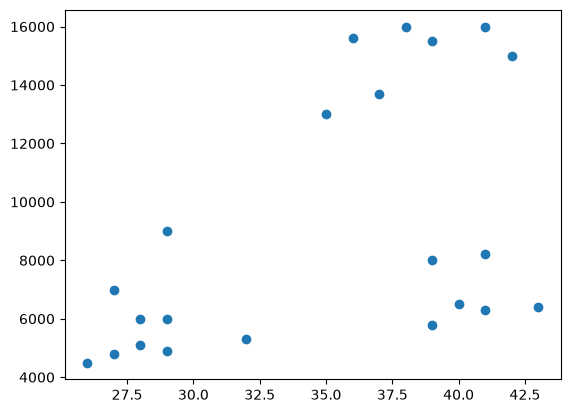

In [10]:
plt.scatter(df["Age"], df["Salary"])

In [11]:
from sklearn.cluster import KMeans

In [12]:
X = df.drop(columns=["Name"])

In [13]:
km = KMeans(n_clusters=3, random_state=0)

In [14]:
km.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[

In [15]:
km.labels_

array([1, 1, 1, 1, 1, 2, 2, 1, 2, 2, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0],
      dtype=int32)

In [16]:
clusters = km.predict(X)

In [17]:
clusters

array([1, 1, 1, 1, 1, 2, 2, 1, 2, 2, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0],
      dtype=int32)

In [18]:
df["cluster"] = clusters

In [19]:
df

,Name,Age,Salary,cluster
0,Ines,29,4900,1
1,Omar,32,5300,1
2,Sabrina,40,6500,1
3,Souad,41,6300,1
4,Nezha,43,6400,1
5,Rabia,39,8000,2
6,Soufiane,41,8200,2
7,Abdellah,39,5800,1
8,Mohamed,27,7000,2
9,Yassine,29,9000,2


In [20]:
cluster1 = df[df["cluster"] == 0]
cluster2 = df[df["cluster"] == 1]
cluster3 = df[df["cluster"] == 2]

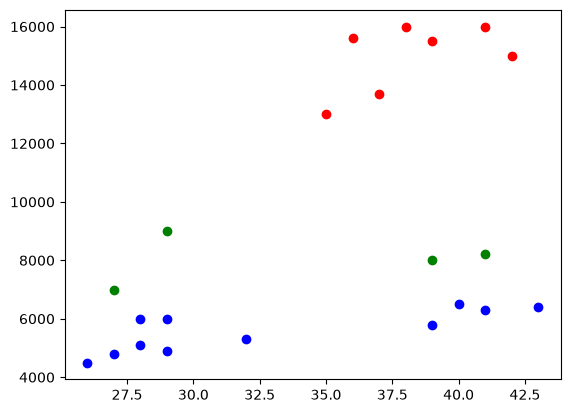

In [21]:
plt.scatter(cluster1['Age'], cluster1['Salary'], color='red', label='Cluster 1')
plt.scatter(cluster2['Age'], cluster2['Salary'], color='blue', label='Cluster 2')
plt.scatter(cluster3['Age'], cluster3['Salary'], color='green', label='Cluster 3')

In [22]:
import seaborn as sns

<Axes: >

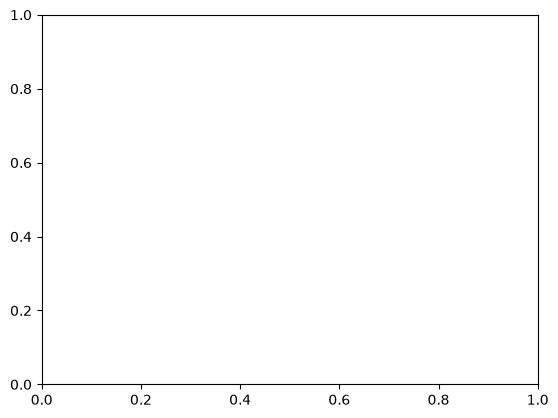

In [23]:
sns.boxplot(X = df["Age"])

In [24]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [25]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

In [26]:
X_scaled

array([[0.17647059, 0.03478261],
       [0.35294118, 0.06956522],
       [0.82352941, 0.17391304],
       [0.88235294, 0.15652174],
       [1.        , 0.16521739],
       [0.76470588, 0.30434783],
       [0.88235294, 0.32173913],
       [0.76470588, 0.11304348],
       [0.05882353, 0.2173913 ],
       [0.17647059, 0.39130435],
       [0.70588235, 1.        ],
       [0.58823529, 0.96521739],
       [0.52941176, 0.73913043],
       [0.64705882, 0.8       ],
       [0.        , 0.        ],
       [0.05882353, 0.02608696],
       [0.11764706, 0.05217391],
       [0.17647059, 0.13043478],
       [0.11764706, 0.13043478],
       [0.94117647, 0.91304348],
       [0.76470588, 0.95652174],
       [0.88235294, 1.        ]])

In [27]:
from sklearn.pipeline import Pipeline

In [38]:
estimator = Pipeline(
    [
        ("Scaler", MinMaxScaler()),
        ("clustering", KMeans(n_clusters=3, random_state=5))
    ]
    )

In [39]:
estimator.fit(X)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Scaler', ...), ('clustering', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['Age','Salary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value


In [46]:
predict = estimator.predict(X)

In [47]:
df["cluster_2"] = predict

In [48]:
df

,Name,Age,Salary,cluster,cluster_2
0,Ines,29,4900,1,1
1,Omar,32,5300,1,1
2,Sabrina,40,6500,1,0
3,Souad,41,6300,1,0
4,Nezha,43,6400,1,0
5,Rabia,39,8000,2,0
6,Soufiane,41,8200,2,0
7,Abdellah,39,5800,1,0
8,Mohamed,27,7000,2,1
9,Yassine,29,9000,2,1


In [51]:
cluster11 = df[df["cluster_2"]==0]
cluster22 = df[df["cluster_2"]==1]
cluster33 = df[df["cluster_2"]==2]

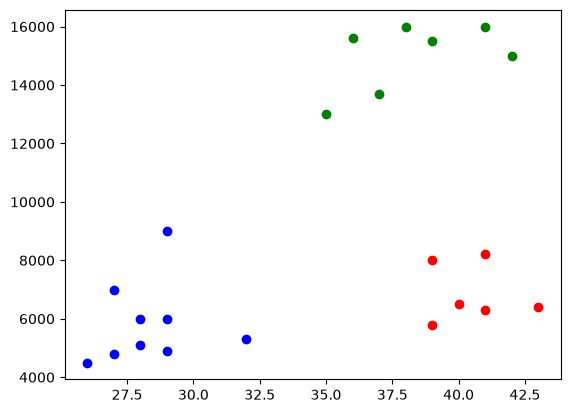

In [52]:
plt.scatter(cluster11['Age'], cluster11['Salary'], color='red', label='Cluster 1')
plt.scatter(cluster22['Age'], cluster22['Salary'], color='blue', label='Cluster 2')
plt.scatter(cluster33['Age'], cluster33['Salary'], color='green', label='Cluster 3')

In [69]:
centroides_scaled = estimator[-1].cluster_centers_

In [70]:
centroides_scaled

array([[0.85294118, 0.2057971 ],
       [0.1372549 , 0.11690821],
       [0.72268908, 0.91055901]])

In [72]:
centroides = estimator[0].inverse_transform(centroides_scaled)

In [73]:
centroides

array([[   40.5       ,  6866.66666667],
       [   28.33333333,  5844.44444444],
       [   38.28571429, 14971.42857143]])

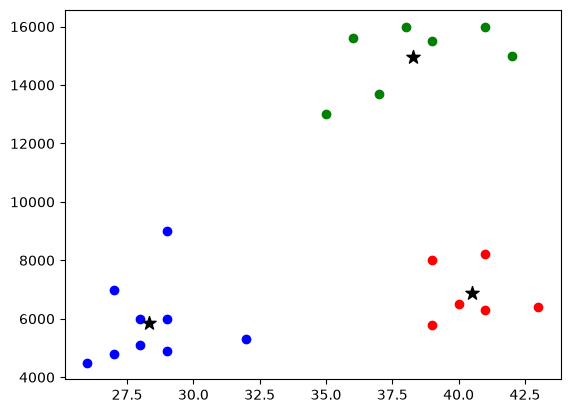

In [74]:
plt.scatter(cluster11['Age'], cluster11['Salary'], color='red', label='Cluster 1')
plt.scatter(cluster22['Age'], cluster22['Salary'], color='blue', label='Cluster 2')
plt.scatter(cluster33['Age'], cluster33['Salary'], color='green', label='Cluster 3')
plt.scatter(centroides[:,0], centroides[:,1], color="black", marker="*", s=100)

In [81]:
from sklearn.metrics import silhouette_score

In [84]:
SSE = []
SIL = []
k_range = range(2, 10)
for k in k_range:
    estimator = Pipeline([("Scaler", MinMaxScaler()), ("clustering", KMeans(n_clusters=k, random_state=5))])
    estimator.fit(X)
    score = estimator[-1].inertia_
    SSE.append(score)
    sil = silhouette_score(X, estimator[-1].labels_)
    SIL.append(sil)


In [78]:
SSE

[5.522140987850921,
 2.139183706762151,
 0.4796830920366221,
 0.3883508960128032,
 0.3374431778716159,
 0.30803132595193106,
 0.20175153597522633,
 0.16166389607104942,
 0.11854107879112952]

In [85]:
SIL

[0.25657476200964113,
 0.35398455359639963,
 0.3715794255335068,
 0.06464865127462657,
 0.03947106570829855,
 0.037224513992648006,
 0.15353955583550255,
 0.07925111657873453]

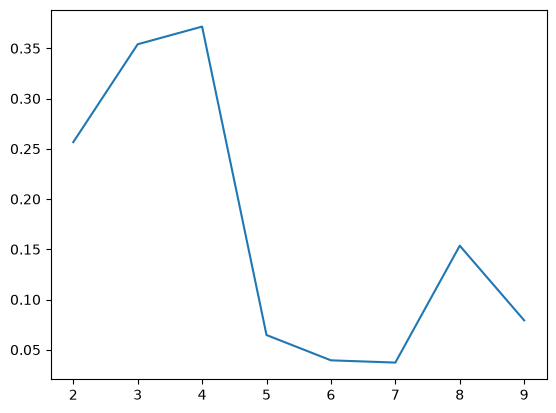

In [87]:
plt.plot(k_range, SIL)

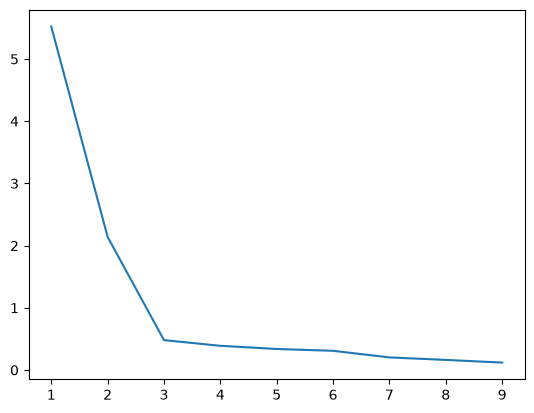

In [80]:
plt.plot(k_range, SSE)

In [88]:
from sklearn import datasets

In [109]:
ds= datasets.load_digits()


In [91]:
ds.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [93]:
data = ds.data
target = ds.target

In [96]:
data.shape

(1797, 64)

In [97]:
data[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [100]:
data[0].reshape(8, 8)

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

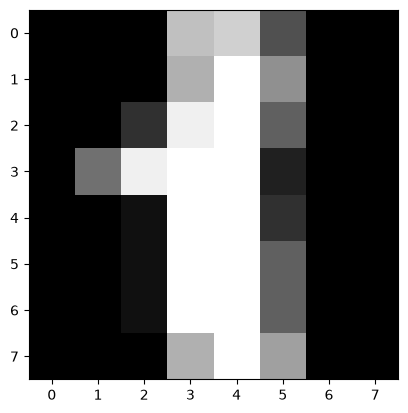

In [105]:
plt.gray()
plt.imshow(data[1].reshape(8, 8))

In [108]:
target[:20]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [129]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [112]:
scaler = StandardScaler()

In [113]:
data_scaled = scaler.fit_transform(data)

In [116]:
X_train, X_test, y_train, y_test = train_test_split(data_scaled, target, test_size=0.3, random_state=5)

In [117]:
model = LogisticRegression()

In [118]:
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [123]:
model.score(X_train, y_train)

0.9984089101034208

In [124]:
model.score(X_test, y_test)

0.9685185185185186

In [126]:
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

In [128]:
print(classification_report(y_train, pred_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       120
           1       0.99      1.00      1.00       130
           2       1.00      1.00      1.00       119
           3       1.00      1.00      1.00       124
           4       1.00      1.00      1.00       138
           5       1.00      1.00      1.00       118
           6       1.00      1.00      1.00       134
           7       1.00      1.00      1.00       120
           8       0.99      0.99      0.99       124
           9       1.00      0.99      1.00       130

    accuracy                           1.00      1257
   macro avg       1.00      1.00      1.00      1257
weighted avg       1.00      1.00      1.00      1257



In [130]:
cm = confusion_matrix(y_train, pred_train)

In [132]:
cm

array([[58,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 51,  0,  1,  0,  0,  0,  0,  0,  0],
       [ 0,  0, 58,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  2, 55,  0,  1,  0,  0,  0,  1],
       [ 0,  2,  0,  0, 40,  0,  0,  1,  0,  0],
       [ 0,  0,  0,  0,  1, 61,  0,  0,  0,  2],
       [ 0,  1,  0,  0,  0,  0, 45,  0,  1,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 58,  0,  1],
       [ 0,  1,  0,  0,  0,  0,  0,  0, 48,  1],
       [ 0,  0,  0,  0,  0,  1,  0,  0,  0, 49]])

<Axes: >

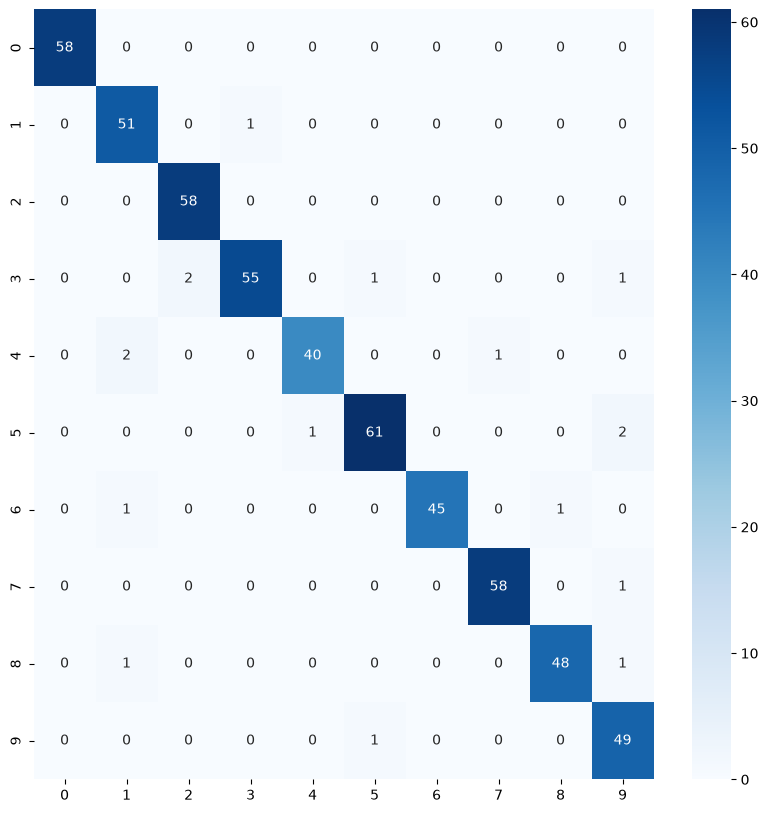

In [134]:
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

In [139]:
df = pd.DataFrame(data=data, columns=ds.feature_names)

In [140]:
df

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0


In [141]:
df["target"] = target

In [142]:
df

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0,9
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0,0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0,8
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0,9


In [144]:
df["target"].value_counts()

target
3    183
1    182
5    182
4    181
6    181
9    180
7    179
0    178
2    177
8    174
Name: count, dtype: int64

In [145]:
from sklearn.decomposition import PCA

In [176]:
pca = PCA(0.95)

In [177]:
data_pca = pca.fit_transform(data_scaled)

In [178]:
data_pca.shape

(1797, 40)

In [189]:
pca.explained_variance_ratio_

array([0.12033916, 0.09561054, 0.08444415, 0.06498408, 0.04860155,
       0.0421412 , 0.03942083, 0.03389381, 0.02998221, 0.02932003,
       0.02781805, 0.02577055, 0.02275303, 0.0222718 , 0.02165229,
       0.01914167, 0.01775547, 0.01638069, 0.0159646 , 0.01489191,
       0.0134797 , 0.01271931, 0.01165837, 0.01057647, 0.00975316,
       0.00944559, 0.00863014, 0.00836643, 0.00797693, 0.00746471,
       0.00725582, 0.00691911, 0.00653909, 0.00640793, 0.00591384,
       0.00571162, 0.00523637, 0.00481808, 0.00453719, 0.00423163])

In [190]:
pca.explained_variance_ratio_.sum()

np.float64(0.9507791125066459)

In [179]:
model2 = LogisticRegression()

In [180]:
X_train, X_test, y_train, y_test = train_test_split(data_pca, target, test_size=0.3, random_state=5)

In [181]:
model2.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [182]:
model2.score(X_train, y_train)

0.9928400954653938

In [183]:
model2.score(X_test, y_test)

0.9685185185185186

In [184]:
pred_train2 = model2.predict(X_train)
pred_test2 = model2.predict(X_test)

In [185]:
print(classification_report(y_train, pred_train2))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       120
           1       0.98      0.98      0.98       130
           2       1.00      1.00      1.00       119
           3       1.00      0.99      1.00       124
           4       1.00      1.00      1.00       138
           5       0.99      0.99      0.99       118
           6       1.00      1.00      1.00       134
           7       1.00      1.00      1.00       120
           8       0.98      0.98      0.98       124
           9       0.98      0.98      0.98       130

    accuracy                           0.99      1257
   macro avg       0.99      0.99      0.99      1257
weighted avg       0.99      0.99      0.99      1257



In [186]:
print(classification_report(y_test, pred_test2))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        58
           1       0.94      0.96      0.95        52
           2       0.97      1.00      0.98        58
           3       0.98      0.97      0.97        59
           4       0.95      0.98      0.97        43
           5       0.97      0.97      0.97        64
           6       1.00      0.98      0.99        47
           7       0.98      0.98      0.98        59
           8       0.98      0.90      0.94        50
           9       0.91      0.96      0.93        50

    accuracy                           0.97       540
   macro avg       0.97      0.97      0.97       540
weighted avg       0.97      0.97      0.97       540



<Axes: >

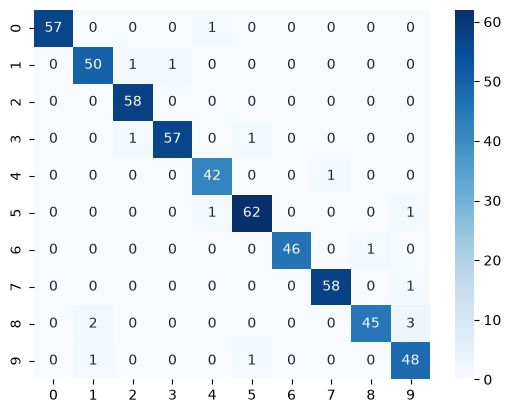

In [ ]:
sns.heatmap(confusion_matrix(y_test, pred_test2), annot=True, fmt="d", cmap="Blues")